In [1]:
# Supply Chain Delivery Performance Analysis
# Advanced Data Analytics for Truckload Operations
#Part 1: Setup and data loading
#Cell 1, title ## 1. Setup
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Settings (change values here only) ----
MIN_OBS = 10          # minimum loads for a destination to be ranked
TRAVEL_SPEED = 40     # mph, used in the Q4 diagnostic
EXTREME_DAYS = 30     # |delay| above this many days is flagged as a suspect record
MIN_ORIGIN_N = 10     # min loads for an origin's own p90 dwell; otherwise network p90
DATA_FOLDER = Path('delivery_data')
FILE_NAMES = ['sample_data1.csv', 'sample_data2.csv', 'sample_data3.csv', 'sample_data4.csv']

os.makedirs('visualizations', exist_ok=True)
plt.rcParams.update({'figure.figsize': (12, 6), 'axes.grid': True, 'grid.alpha': 0.3})
print("Setup complete")

Setup complete


In [2]:
##Cell2 2. Load and combine the four CSV files
# Read ID columns as text so one bad cell can't change a column's type
frames = [pd.read_csv(DATA_FOLDER / name, dtype={'ORIG': str, 'DEST': str})
          for name in FILE_NAMES]
df = pd.concat(frames, ignore_index=True)
raw_rows = len(df)
print(f"Raw rows loaded (4 files): {raw_rows:,}")

# Convert IDs to numbers; non-numeric values (e.g. Excel's #VALUE!) become missing
for col in ['ORIG', 'DEST']:
    df[col] = pd.to_numeric(df[col].str.strip(), errors='coerce')

bad_ids = df['ORIG'].isna() | df['DEST'].isna()
ids_removed = int(bad_ids.sum())
print(f"Rows removed for invalid ORIG/DEST: {ids_removed:,}")
df = df[~bad_ids].copy()

# Store location codes as text labels, not numbers
df['ORIG'] = df['ORIG'].astype('int64').astype(str)
df['DEST'] = df['DEST'].astype('int64').astype(str)
print(f"Rows after ID cleaning: {len(df):,}")

Raw rows loaded (4 files): 59,529
Rows removed for invalid ORIG/DEST: 1
Rows after ID cleaning: 59,528


In [3]:
#Cell 3, title ## 3. Validate the location IDs
assert df['DEST'].map(type).eq(str).all(), "DEST still has mixed types"
assert df['ORIG'].map(type).eq(str).all(), "ORIG still has mixed types"
print("Origins:", df['ORIG'].nunique(), "| Destinations:", df['DEST'].nunique())
print("Loads for destination 1822349 (expect 61):", (df['DEST'] == '1822349').sum())

Origins: 1680 | Destinations: 2347
Loads for destination 1822349 (expect 61): 61


In [4]:
 # Cell 4, title ## 4. Explore the data
print("Shape:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum())
df.head()

Shape: (59528, 22)

Missing values per column:
LOAD_ID                    0
BOOKING_DT                 0
BOOKING_TM                 0
ORIG                       0
PKUP_ST_DT                 0
PKUP_ST_TM                 0
PKUP_END_DT                0
PKUP_END_TM                0
PKUP_ARRIVAL_ACT_DT        0
PKUP_ARRIVAL_ACT_TM        0
PKUP_DEPARTURE_ACT_DT      0
PKUP_DEPARTURE_ACT_TM      0
DEST                       0
DLVERY_ST_DT               0
DLVERY_ST_TM               0
DLVERY_END_DT              0
DLVERY_END_TM              0
DLVERY_ARRIVAL_ACT_DT      0
DLVERY_ARRIVAL_ACT_TM      0
DLVERY_DEPARTURE_ACT_DT    0
DLVERY_DEPARTURE_ACT_TM    0
MILEAGE                    0
dtype: int64


,LOAD_ID,BOOKING_DT,BOOKING_TM,ORIG,PKUP_ST_DT,PKUP_ST_TM,PKUP_END_DT,PKUP_END_TM,PKUP_ARRIVAL_ACT_DT,PKUP_ARRIVAL_ACT_TM,...,DEST,DLVERY_ST_DT,DLVERY_ST_TM,DLVERY_END_DT,DLVERY_END_TM,DLVERY_ARRIVAL_ACT_DT,DLVERY_ARRIVAL_ACT_TM,DLVERY_DEPARTURE_ACT_DT,DLVERY_DEPARTURE_ACT_TM,MILEAGE
0,1,20200903,1312,2075615,20200905,700,20200905,700,20200905,1015,...,1047897,20200909,1,20200910,130,20200910,102,20200910,352,1034
1,2,20201001,845,2059975,20201002,1100,20201002,1100,20201002,907,...,659549,20201005,1800,20201005,1800,20201005,1106,20201005,1107,828
2,3,20210216,1411,1041675,20210226,830,20210226,2000,20210226,1520,...,1135821,20210310,1700,20210310,1700,20210310,1532,20210310,1818,529
3,4,20200524,1000,1128953,20200526,700,20200527,2000,20200527,1334,...,992647,20200601,1100,20200601,1100,20200601,1040,20200601,1548,799
4,5,20200529,1458,1308541,20200605,1100,20200605,1100,20200605,1008,...,679813,20200608,1200,20200608,1200,20200608,1200,20200608,1200,1365


## Part 2: Dates, cleaning and metrics

In [5]:
##Cell 5, Convert dates and times
# new column name: (date column, time column)
datetime_map = {
    'booking_datetime':          ('BOOKING_DT', 'BOOKING_TM'),
    'pickup_start_datetime':     ('PKUP_ST_DT', 'PKUP_ST_TM'),
    'pickup_end_datetime':       ('PKUP_END_DT', 'PKUP_END_TM'),
    'pickup_arrival_actual':     ('PKUP_ARRIVAL_ACT_DT', 'PKUP_ARRIVAL_ACT_TM'),
    'pickup_departure_actual':   ('PKUP_DEPARTURE_ACT_DT', 'PKUP_DEPARTURE_ACT_TM'),
    'delivery_start_datetime':   ('DLVERY_ST_DT', 'DLVERY_ST_TM'),
    'delivery_end_datetime':     ('DLVERY_END_DT', 'DLVERY_END_TM'),
    'delivery_arrival_actual':   ('DLVERY_ARRIVAL_ACT_DT', 'DLVERY_ARRIVAL_ACT_TM'),
    'delivery_departure_actual': ('DLVERY_DEPARTURE_ACT_DT', 'DLVERY_DEPARTURE_ACT_TM'),
}

for new_col, (date_col, time_col) in datetime_map.items():
    text = (df[date_col].astype(str).str.strip() + ' ' +
            df[time_col].astype(str).str.strip().str.zfill(4))
    df[new_col] = pd.to_datetime(text, format='%Y%m%d %H%M', errors='coerce')

print("Datetime columns created:", len(datetime_map))

Datetime columns created: 9


In [6]:
#Cell 6, title ## 6. Check for missing datetimes
dt_cols = list(datetime_map.keys())
print("Missing datetimes per column (before cleaning):")
print(df[dt_cols].isna().sum())

Missing datetimes per column (before cleaning):
booking_datetime               0
pickup_start_datetime          0
pickup_end_datetime            0
pickup_arrival_actual        357
pickup_departure_actual      367
delivery_start_datetime        0
delivery_end_datetime          0
delivery_arrival_actual      429
delivery_departure_actual    438
dtype: int64


In [7]:
#Cell 7, title ## 7. Remove loads without delivery times

In [8]:
rows_before_clean = len(df)
df = df.dropna(subset=['delivery_arrival_actual', 'delivery_end_datetime']).copy()
rows_removed = rows_before_clean - len(df)

print(f"Removed (missing delivery data): {rows_removed:,}")
print(f"Analyzable loads: {len(df):,}")

Removed (missing delivery data): 429
Analyzable loads: 59,099


In [9]:
#Cell 8, title ## 8. Calculate performance metrics
# Positive = late, negative = early
df['delivery_delay_hours'] = (df['delivery_arrival_actual'] -
                              df['delivery_end_datetime']).dt.total_seconds() / 3600

# Two on-time definitions: the case study says "before" the window end
df['is_on_time'] = df['delivery_delay_hours'] <= 0           # arrival at or before window end
df['is_on_time_strict'] = df['delivery_delay_hours'] < 0     # arrival strictly before

df['pickup_dwell_hours'] = (df['pickup_departure_actual'] -
                            df['pickup_arrival_actual']).dt.total_seconds() / 3600

print(f"On-time (<= window end):   {df['is_on_time'].mean()*100:.1f}%")
print(f"On-time (strictly before): {df['is_on_time_strict'].mean()*100:.1f}%")

On-time (<= window end):   75.0%
On-time (strictly before): 73.0%


In [10]:
#Cell 9, title ## 9. Flag suspect records
window_days = (df['delivery_end_datetime'] - df['delivery_start_datetime']).dt.days

df['flag_window_reversed'] = window_days < 0
df['flag_window_over_7d'] = window_days > 7
df['flag_extreme_delay'] = df['delivery_delay_hours'].abs() > EXTREME_DAYS * 24
df['flag_any'] = df[['flag_window_reversed', 'flag_window_over_7d', 'flag_extreme_delay']].any(axis=1)

print(f"Window ends before it starts: {df['flag_window_reversed'].sum():,}")
print(f"Window longer than 7 days:    {df['flag_window_over_7d'].sum():,}")
print(f"Extreme late (> {EXTREME_DAYS}d):      {(df['delivery_delay_hours'] > EXTREME_DAYS*24).sum():,}")
print(f"Extreme early (> {EXTREME_DAYS}d):     {(df['delivery_delay_hours'] < -EXTREME_DAYS*24).sum():,}")
print(f"Total flagged: {df['flag_any'].sum():,} ({df['flag_any'].mean()*100:.2f}% of loads)")

clean = df[~df['flag_any']]
print(f"\nOn-time (<= end), all data:    {df['is_on_time'].mean()*100:.2f}%")
print(f"On-time (<= end), flagged out: {clean['is_on_time'].mean()*100:.2f}%")

Window ends before it starts: 57
Window longer than 7 days:    28
Extreme late (> 30d):      5
Extreme early (> 30d):     13
Total flagged: 90 (0.15% of loads)

On-time (<= end), all data:    74.96%
On-time (<= end), flagged out: 74.99%


In [11]:
#Flagged records are marked, not deleted. clean is the version without them.

#Cell 10, title ## 10. Dataset summary (numbers for the README)
dest_counts = df['DEST'].value_counts()
qualified = dest_counts[dest_counts >= MIN_OBS]

print(f"Raw rows loaded (4 files):         {raw_rows:,}")
print(f"Removed (invalid destination ID):  {ids_removed:,}")
print(f"Removed (missing delivery data):   {rows_removed:,}")
print(f"Analyzable loads:                  {len(df):,}")
print(f"Origins / destinations:            {df['ORIG'].nunique():,} / {df['DEST'].nunique():,}")
print(f"Delivery arrivals span:            {df['delivery_arrival_actual'].min().date()} to {df['delivery_arrival_actual'].max().date()}")
print(f"Average mileage:                   {df['MILEAGE'].mean():.0f}")
print(f"Overall on-time (<= window end):   {df['is_on_time'].mean()*100:.1f}%")
print(f"Overall on-time (strictly before): {df['is_on_time_strict'].mean()*100:.1f}%")
print(f"Destinations with >= {MIN_OBS} loads:    {len(qualified):,} of {len(dest_counts):,}")
print(f"Share of loads they cover:         {qualified.sum() / len(df) * 100:.1f}%")

Raw rows loaded (4 files):         59,529
Removed (invalid destination ID):  1
Removed (missing delivery data):   429
Analyzable loads:                  59,099
Origins / destinations:            1,676 / 2,343
Delivery arrivals span:            2020-05-02 to 2021-12-13
Average mileage:                   459
Overall on-time (<= window end):   75.0%
Overall on-time (strictly before): 73.0%
Destinations with >= 10 loads:    463 of 2,343
Share of loads they cover:         92.7%


## Part 3: Question 2, does the data support the customer's claim?

In [12]:
#Cell 11, title ## 11. Q2: on-time rate and size of delays
delay = df['delivery_delay_hours']
late = delay[delay > 0]

print(f"On-time (<= window end):   {df['is_on_time'].mean()*100:.1f}%   (customer believes ~90%)")
print(f"On-time (strictly before): {df['is_on_time_strict'].mean()*100:.1f}%")

print(f"\nLate loads: {len(late):,}")
print(f"Median delay when late:      {late.median():.1f} h")
print(f"90th percentile delay:       {late.quantile(0.90):.1f} h")
print(f"99th percentile delay:       {late.quantile(0.99):.1f} h")
print(f"Share of late loads > 2h:    {(late > 2).mean()*100:.1f}%")
print(f"Share of ALL loads > 2h late: {(delay > 2).mean()*100:.1f}%")

On-time (<= window end):   75.0%   (customer believes ~90%)
On-time (strictly before): 73.0%

Late loads: 14,798
Median delay when late:      5.5 h
90th percentile delay:       36.1 h
99th percentile delay:       106.8 h
Share of late loads > 2h:    66.4%
Share of ALL loads > 2h late: 16.6%


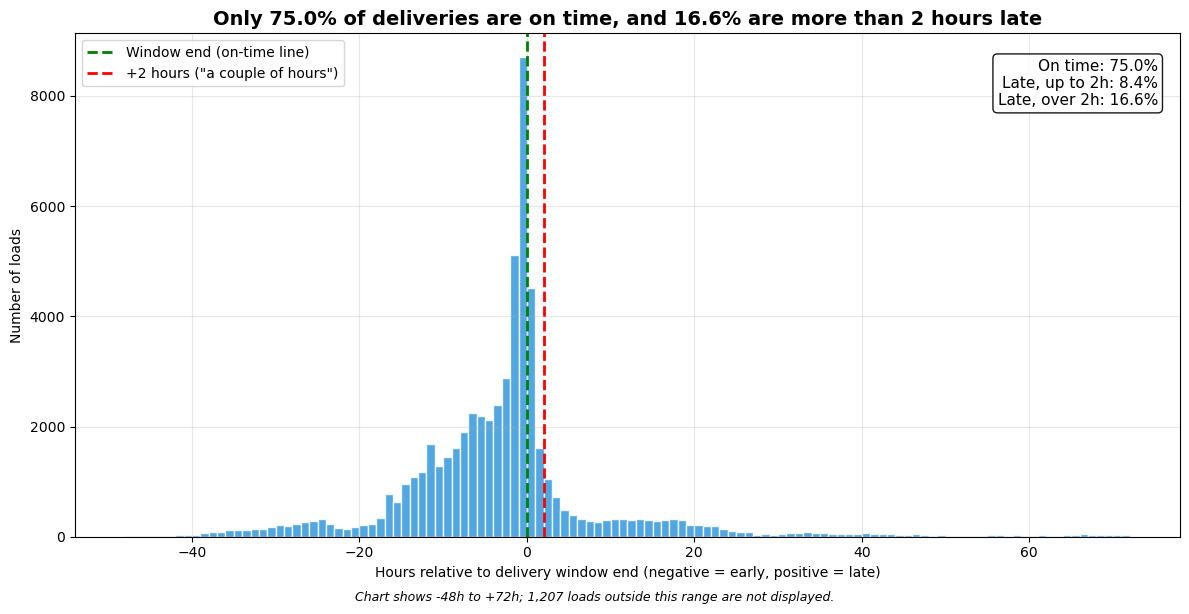

In [13]:
#Cell 12, title ## 12. Q2 plot: delay distribution for all loads
on_time_pct = (delay <= 0).mean() * 100
late_2h_pct = ((delay > 0) & (delay <= 2)).mean() * 100
late_over_2h_pct = (delay > 2).mean() * 100

view = delay[(delay >= -48) & (delay <= 72)]      # zoom so extreme records don't squash the chart
hidden = len(delay) - len(view)

fig, ax = plt.subplots()
ax.hist(view, bins=120, color='#3498db', alpha=0.85, edgecolor='white')
ax.axvline(0, color='green', linestyle='--', linewidth=2, label='Window end (on-time line)')
ax.axvline(2, color='red', linestyle='--', linewidth=2, label='+2 hours ("a couple of hours")')

ax.set_title(f'Only {on_time_pct:.1f}% of deliveries are on time, '
             f'and {late_over_2h_pct:.1f}% are more than 2 hours late',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Hours relative to delivery window end (negative = early, positive = late)')
ax.set_ylabel('Number of loads')
ax.legend(loc='upper left')

summary = (f"On time: {on_time_pct:.1f}%\nLate, up to 2h: {late_2h_pct:.1f}%\n"
           f"Late, over 2h: {late_over_2h_pct:.1f}%")
ax.text(0.98, 0.95, summary, transform=ax.transAxes, ha='right', va='top', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
fig.text(0.5, -0.01, f"Chart shows -48h to +72h; {hidden:,} loads outside this range are not displayed.",
         ha='center', fontsize=9, style='italic')

fig.tight_layout()
fig.savefig('visualizations/q2_delay_distribution.png', dpi=200, bbox_inches='tight')
plt.show()

## Part 4: Question 3, problem locations

In [14]:
#Cell 13, title ## 13. Q3a: bottom 5 destinations by on-time %
g = df.groupby('DEST')
dest_stats = pd.DataFrame({
    'n': g.size(),
    'on_time_n': g['is_on_time'].sum(),
    'median_delay_h': g['delivery_delay_hours'].median(),
    'max_delay_h': g['delivery_delay_hours'].max(),
})
dest_stats['on_time_pct'] = dest_stats['on_time_n'] / dest_stats['n'] * 100
dest_stats = dest_stats[dest_stats['n'] >= MIN_OBS].copy()

def wilson_ci(k, n, z=1.96):
    """95% Wilson confidence interval for a proportion, in percent."""
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (center - half) * 100, (center + half) * 100

bottom5 = (dest_stats
           .sort_values(['on_time_pct', 'median_delay_h'], ascending=[True, False])
           .head(5).copy())

bounds = [wilson_ci(k, n) for k, n in zip(bottom5['on_time_n'], bottom5['n'])]
bottom5['ci_low_pct'] = [b[0] for b in bounds]
bottom5['ci_high_pct'] = [b[1] for b in bounds]

tied = (dest_stats['on_time_pct'].round(1) == round(bottom5['on_time_pct'].iloc[-1], 1)).sum()
print(f"Destinations tied at the 5th-worst rate: {tied}")
bottom5.round(1)

Destinations tied at the 5th-worst rate: 2


,n,on_time_n,median_delay_h,max_delay_h,on_time_pct,ci_low_pct,ci_high_pct
DEST,,,,,,,
906049,14,2,0.5,26.8,14.3,4.0,39.9
1288141,13,2,4.1,23.6,15.4,4.3,42.2
971635,21,5,1.2,69.4,23.8,10.6,45.1
499477,34,11,0.4,27.4,32.4,19.1,49.2
594983,182,65,5.1,102.0,35.7,29.1,42.9


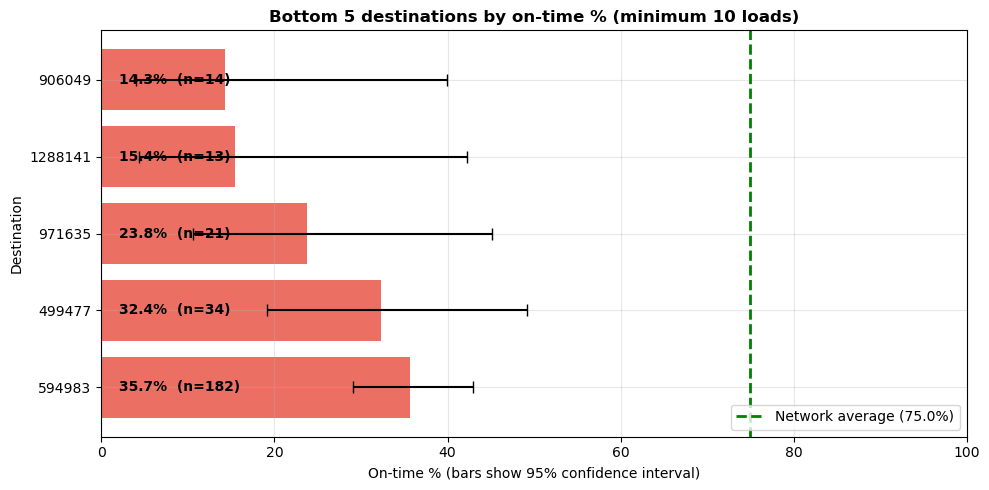

In [15]:
#Cell 14, title ## 14. Q3a plot
network_on_time = df['is_on_time'].mean() * 100
labels = bottom5.index.tolist()
pct = bottom5['on_time_pct'].values
err = [pct - bottom5['ci_low_pct'].values, bottom5['ci_high_pct'].values - pct]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(labels, pct, xerr=err, color='#e74c3c', alpha=0.8, capsize=4)
ax.axvline(network_on_time, color='green', linestyle='--', linewidth=2,
           label=f'Network average ({network_on_time:.1f}%)')
for i, (p, n) in enumerate(zip(pct, bottom5['n'])):
    ax.text(2, i, f"{p:.1f}%  (n={n})", va='center', fontsize=10, fontweight='bold')
ax.set_xlim(0, 100)
ax.set_xlabel('On-time % (bars show 95% confidence interval)')
ax.set_ylabel('Destination')
ax.set_title(f'Bottom 5 destinations by on-time % (minimum {MIN_OBS} loads)', fontweight='bold')
ax.legend(loc='lower right')
ax.invert_yaxis()
fig.tight_layout()
fig.savefig('visualizations/q3_bottom5_locations.png', dpi=200, bbox_inches='tight')
plt.show()

In [16]:
#Cell 15, title ## 15. Q3b: destinations with the highest delay variability
def dest_std_table(data, min_n=MIN_OBS):
    g = data.groupby('DEST')['delivery_delay_hours']
    t = pd.DataFrame({
        'n': g.size(),
        'std_hours': g.std(),
        'iqr_hours': g.quantile(0.75) - g.quantile(0.25),   # spread that ignores outliers
        'median_hours': g.median(),
        'min_hours': g.min(),
        'max_hours': g.max(),
    })
    return t[t['n'] >= min_n].round(1)

print("TOP 5 BY STANDARD DEVIATION (raw data, as the case study asks):")
top5_raw = dest_std_table(df).nlargest(5, 'std_hours')
print(top5_raw)

print(f"\nTOP 5 BY STANDARD DEVIATION (records more than {EXTREME_DAYS} days off, "
      "and other flagged records, excluded):")
top5_clean = dest_std_table(clean).nlargest(5, 'std_hours')
print(top5_clean)

TOP 5 BY STANDARD DEVIATION (raw data, as the case study asks):
           n  std_hours  iqr_hours  median_hours  min_hours  max_hours
DEST                                                                  
1492753   22     1397.3        8.7         -13.5    -6565.4       12.2
1012707   54     1201.0        2.2          -0.2      -49.6     8824.0
53363    106      706.6        4.1          -1.6      -44.3     7271.3
1302285   77      419.4        4.5          -4.5    -3675.8       79.2
2061913   28      417.8        1.8          -0.3    -2209.6       25.2

TOP 5 BY STANDARD DEVIATION (records more than 30 days off, and other flagged records, excluded):
          n  std_hours  iqr_hours  median_hours  min_hours  max_hours
DEST                                                                 
1822349  60       99.6      167.0         -90.9     -322.2       50.4
1599683  14       59.2       96.3          -8.3     -148.8       16.5
1281579  12       54.4        8.8          -2.5     -142.9  

## Part 5: Question 4, diagnostic test

In [17]:
#Cell 16, title ## 16. Q4: set up the diagnostic

In [18]:
worst_destination = bottom5.index[0]
worst_location_data = df[df['DEST'] == worst_destination].copy()

print(f"Worst destination: {worst_destination}")
print(f"Loads: {len(worst_location_data)}")
print(f"Current on-time rate: {worst_location_data['is_on_time'].mean()*100:.1f}%")
print(f"Flagged suspect records among these loads: {int(worst_location_data['flag_any'].sum())}")

# 90th percentile dwell time per origin (only origins with enough loads)
origin_p90_all = df.groupby('ORIG')['pickup_dwell_hours'].quantile(0.90)
origin_n = df['ORIG'].value_counts()
origin_p90 = origin_p90_all[origin_n.reindex(origin_p90_all.index) >= MIN_ORIGIN_N]
network_p90 = df['pickup_dwell_hours'].quantile(0.90)

print(f"Origins with enough loads for their own p90: {len(origin_p90):,} of {len(origin_p90_all):,}")
print(f"Network-wide p90 dwell (fallback): {network_p90:.2f} h")

Worst destination: 906049
Loads: 14
Current on-time rate: 14.3%
Flagged suspect records among these loads: 0
Origins with enough loads for their own p90: 337 of 1,676
Network-wide p90 dwell (fallback): 3.35 h


In [19]:
#Cell 17, title ## 17. Q4: run the diagnostic
w = worst_location_data.copy()

# Driver arrives at pickup window start, waits p90 dwell, then drives at TRAVEL_SPEED
w['dwell_used_h'] = w['ORIG'].map(origin_p90).fillna(network_p90)
w['transit_h'] = w['MILEAGE'] / TRAVEL_SPEED

w['optimal_pickup_departure'] = w['pickup_start_datetime'] + pd.to_timedelta(w['dwell_used_h'], unit='h')
w['optimal_delivery_arrival'] = w['optimal_pickup_departure'] + pd.to_timedelta(w['transit_h'], unit='h')

# Negative = would arrive before the window end
w['difference_hours'] = (w['optimal_delivery_arrival'] -
                         w['delivery_end_datetime']).dt.total_seconds() / 3600
w['optimal_delivery_arrival'] = w['optimal_delivery_arrival'].dt.round('min')
w['would_be_on_time'] = w['difference_hours'] <= 0

diagnostic_df = w[['LOAD_ID', 'ORIG', 'MILEAGE', 'dwell_used_h', 'transit_h',
                   'optimal_delivery_arrival', 'delivery_end_datetime',
                   'difference_hours', 'would_be_on_time']]

n_tested = len(diagnostic_df)
n_ok = int(diagnostic_df['would_be_on_time'].sum())
print(f"Loads tested: {n_tested}")
print(f"Could meet the window under ideal conditions: {n_ok} ({n_ok / n_tested * 100:.0f}%)")
print(f"Median slack: {-diagnostic_df['difference_hours'].median():.1f} h "
      f"(negative = would arrive late)")
print(f"Average slack: {-diagnostic_df['difference_hours'].mean():.1f} h")
print("\nAssumptions: arrive at pickup window start; dwell = p90 for the origin "
      f"(network p90 if origin has < {MIN_ORIGIN_N} loads); {TRAVEL_SPEED} mph constant; no rest breaks.")
diagnostic_df.round(1)

Loads tested: 14
Could meet the window under ideal conditions: 13 (93%)
Median slack: 10.8 h (negative = would arrive late)
Average slack: 25.0 h

Assumptions: arrive at pickup window start; dwell = p90 for the origin (network p90 if origin has < 10 loads); 40 mph constant; no rest breaks.


,LOAD_ID,ORIG,MILEAGE,dwell_used_h,transit_h,optimal_delivery_arrival,delivery_end_datetime,difference_hours,would_be_on_time
40348,40349,1324589,460,1.0,11.5,2020-11-12 04:28:00,2020-11-16 08:45:00,-100.3,True
40349,40350,1324589,460,1.0,11.5,2020-11-18 04:28:00,2020-11-18 08:15:00,-3.8,True
40350,40351,1324589,460,1.0,11.5,2020-11-21 04:28:00,2020-11-23 08:30:00,-52.0,True
43831,43832,1324589,460,1.0,11.5,2021-01-04 20:28:00,2021-01-05 08:15:00,-11.8,True
47802,47803,1324589,460,1.0,11.5,2021-01-20 20:28:00,2021-01-21 10:15:00,-13.8,True
47803,47804,1324589,460,1.0,11.5,2021-01-27 20:28:00,2021-01-27 08:00:00,12.5,False
50367,50368,1324589,460,1.0,11.5,2021-02-06 01:28:00,2021-02-08 08:45:00,-55.3,True
50653,50654,1324589,460,1.0,11.5,2021-02-10 22:28:00,2021-02-11 09:00:00,-10.5,True
50654,50655,1324589,460,1.0,11.5,2021-02-17 21:43:00,2021-02-18 08:15:00,-10.5,True
53298,53299,1324589,460,1.0,11.5,2021-03-17 02:28:00,2021-03-17 07:45:00,-5.3,True


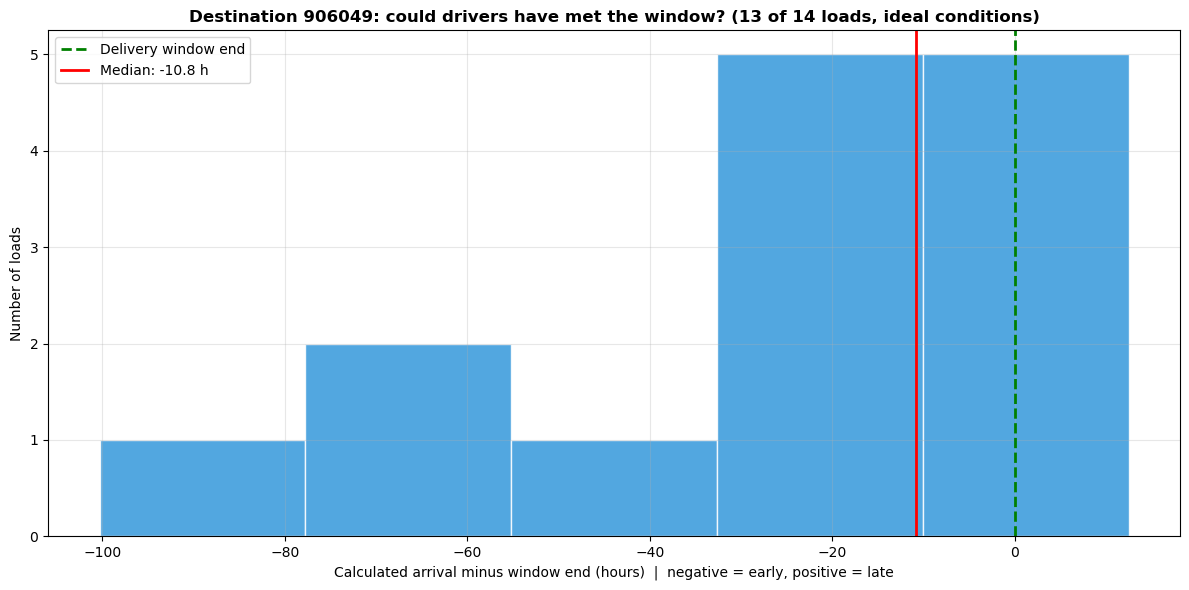

In [20]:
#Cell 18, title ## 18. Q4 plot: calculated arrival vs window end
diff = diagnostic_df['difference_hours']

fig, ax = plt.subplots()
ax.hist(diff, bins='auto', color='#3498db', alpha=0.85, edgecolor='white')
ax.axvline(0, color='green', linestyle='--', linewidth=2, label='Delivery window end')
ax.axvline(diff.median(), color='red', linewidth=2, label=f'Median: {diff.median():.1f} h')
ax.set_xlabel('Calculated arrival minus window end (hours)  |  negative = early, positive = late')
ax.set_ylabel('Number of loads')
ax.set_title(f'Destination {worst_destination}: could drivers have met the window? '
             f'({n_ok} of {n_tested} loads, ideal conditions)', fontweight='bold')
ax.legend()
fig.tight_layout()
fig.savefig('visualizations/q4_diagnostic.png', dpi=200, bbox_inches='tight')
plt.show()

In [21]:
#Cell 19 (optional but valuable), title ## 19. Where did the time actually go?
d = worst_location_data.copy()
d['pickup_late_h'] = (d['pickup_arrival_actual'] - d['pickup_start_datetime']).dt.total_seconds() / 3600
d['dwell_actual_h'] = d['pickup_dwell_hours']
d['dwell_used_h'] = d['ORIG'].map(origin_p90).fillna(network_p90)
d['dwell_excess_h'] = d['dwell_actual_h'] - d['dwell_used_h']
d['transit_actual_h'] = (d['delivery_arrival_actual'] - d['pickup_departure_actual']).dt.total_seconds() / 3600
d['transit_excess_h'] = d['transit_actual_h'] - d['MILEAGE'] / TRAVEL_SPEED
d['origin_n'] = d['ORIG'].map(origin_n)

cols = ['LOAD_ID', 'MILEAGE', 'pickup_late_h', 'dwell_excess_h', 'transit_excess_h',
        'delivery_delay_hours', 'origin_n']
d[cols].round(1)

,LOAD_ID,MILEAGE,pickup_late_h,dwell_excess_h,transit_excess_h,delivery_delay_hours,origin_n
40348,40349,460,-1.5,-1.0,104.5,1.8,2565
40349,40350,460,2.4,0.1,7.9,6.6,2565
40350,40351,460,-1.2,-1.0,54.3,0.2,2565
43831,43832,460,6.0,0.6,10.8,5.6,2565
47802,47803,460,0.7,0.4,11.7,-1.0,2565
47803,47804,460,3.2,0.5,10.7,26.8,2565
50367,50368,460,-4.4,-0.2,60.3,0.4,2565
50653,50654,460,0.3,1.9,34.2,25.9,2565
50654,50655,460,-0.4,0.6,10.5,0.2,2565
53298,53299,460,-2.2,0.1,7.8,0.4,2565


## Extra

In [22]:
#1. Show the tied destination.
tie_rate = round(bottom5['on_time_pct'].iloc[-1], 1)
dest_stats[dest_stats['on_time_pct'].round(1) == tie_rate]

,n,on_time_n,median_delay_h,max_delay_h,on_time_pct
DEST,,,,,
1498907,14,5,0.825,34.966667,35.714286
594983,182,65,5.125,102.050000,35.714286


In [23]:
#2. Grace-period sensitivity. Displying how many "late" loads are near-misses:
rows = [{'grace_minutes': m,
         'on_time_pct': (df['delivery_delay_hours'] <= m / 60).mean() * 100}
        for m in [0, 15, 30, 60, 120]]
pd.DataFrame(rows).round(1)

,grace_minutes,on_time_pct
0,0,75.0
1,15,77.1
2,30,78.6
3,60,80.7
4,120,83.4


In [24]:
#3. Window length for destination 1822349:
x = df[df['DEST'] == '1822349'].copy()
x['window_len_h'] = (x['delivery_end_datetime'] - x['delivery_start_datetime']).dt.total_seconds() / 3600
net_len = (df['delivery_end_datetime'] - df['delivery_start_datetime']).dt.total_seconds() / 3600
print(x['window_len_h'].describe().round(1))
print("Network median window length (h):", round(net_len.median(), 1))

count     61.0
mean      10.6
std       42.8
min        0.0
25%        0.0
50%        0.0
75%        0.0
max      240.0
Name: window_len_h, dtype: float64
Network median window length (h): 1.0


In [25]:
#4. Rest-break sensitivity for Q4:
DRIVE_LIMIT_H, REST_H = 11, 10      # simplified hours-of-service rule

w2 = worst_location_data.copy()
w2['dwell_used_h'] = w2['ORIG'].map(origin_p90).fillna(network_p90)
drive_h = w2['MILEAGE'] / TRAVEL_SPEED
w2['transit_rest_h'] = drive_h + (np.ceil(drive_h / DRIVE_LIMIT_H) - 1) * REST_H
arrival = w2['pickup_start_datetime'] + pd.to_timedelta(w2['dwell_used_h'] + w2['transit_rest_h'], unit='h')
w2['diff_rest_h'] = (arrival - w2['delivery_end_datetime']).dt.total_seconds() / 3600

print(f"Feasible with rest breaks: {(w2['diff_rest_h'] <= 0).sum()} of {len(w2)}")
print(f"Median slack: {-w2['diff_rest_h'].median():.1f} h")

Feasible with rest breaks: 9 of 14
Median slack: 0.8 h


In [26]:
#5. what tolerance would reach 90%
df['delivery_delay_hours'].quantile(0.90)

10.3

In [27]:
print("\n" + "=" * 70)
print("End of analysis")
print("=" * 70)


End of analysis
